# Synthetic world — expected effects (Checkpoint 1B)

Reads `data/generated` (run `uv run tp gen` first) and shows that the causal effects configured in
`config/datagen/*.yaml` are present and recoverable from **observable** tables. The same checks are
enforced by `uv run tp validate-data` (the learnability gate, §7.8).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

D = Path("../data/generated") if Path("../data/generated").exists() else Path("data/generated")
read = lambda name: pd.read_parquet(D / f"{name}.parquet")
manifest = json.loads((D / "manifest.json").read_text())
print({k: manifest[k] for k in ("scale", "seed", "anchor", "history_days")})
pd.Series(manifest["row_counts"]).sort_values(ascending=False).head(12)

{'scale': 'full', 'seed': 42, 'anchor': '2026-09-24', 'history_days': 180}


sensor_1min               1960133
cycles                     852774
telemetry_1min             120960
truth_ground_hourly        120528
weather_forecast            70272
fatigue_samples             24754
truth_operator_state        24754
truth_component_health      24300
truth_behavior_labels       16373
idle_windows                15416
behavior_events             15155
truth_weather_hourly        13392
dtype: int64

## 1. Cycle time responds to rain, wet ground, heat, skill and machine health (§7.4)

Effects are estimated from observable tables with the same feature builder the learnability gate uses.

expected signs hold: True | inconclusive: none


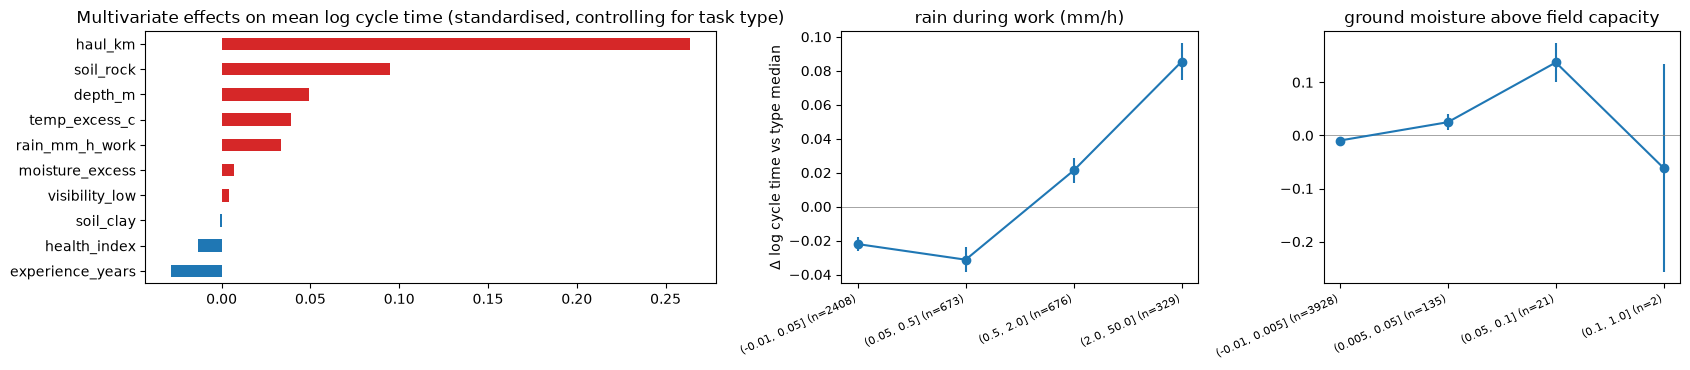

In [2]:
from terrapilot.core.config import load_config
from terrapilot.datagen.validate import task_features, _signs

cfg = load_config(Path("../config") if Path("../config").exists() else Path("config"))
tf = task_features(D, cfg).assign(y=lambda d: d["y_cycle"])            # observable features only
feats = cfg.models["learnability"]["targets"]["cycle_time_effects"]["features"]
coefs, wrong, unsure = _signs(tf, feats, {}, pd.get_dummies(tf["type"], dtype=float))

fig, ax = plt.subplots(1, 3, figsize=(17, 3.8), gridspec_kw={"width_ratios": [1.6, 1, 1]})
pd.Series(coefs).sort_values().plot.barh(ax=ax[0], color=["tab:red" if v > 0 else "tab:blue" for v in pd.Series(coefs).sort_values()])
ax[0].set_title("Multivariate effects on mean log cycle time (standardised, controlling for task type)")
tf["resid"] = tf["y_cycle"] - tf.groupby("type")["y_cycle"].transform("median")
for a, (col, bins, label) in zip(ax[1:], [
    ("rain_mm_h_work", [-0.01, 0.05, 0.5, 2, 50], "rain during work (mm/h)"),
    ("moisture_excess", [-0.01, 0.005, 0.05, 0.1, 1], "ground moisture above field capacity"),
]):
    g = tf.groupby(pd.cut(tf[col], bins), observed=True)["resid"].agg(["mean", "sem", "count"])
    a.errorbar(range(len(g)), g["mean"], yerr=g["sem"], marker="o"); a.axhline(0, color="grey", lw=0.5)
    a.set_xticks(range(len(g)), [f"{i} (n={n})" for i, n in zip(g.index, g["count"])], fontsize=8, rotation=25, ha="right"); a.set_title(label)
ax[1].set_ylabel("Δ log cycle time vs type median")
plt.tight_layout()
print("expected signs hold:", not wrong, "| inconclusive:", unsure or "none")

## 2. Clay is slowed by wet ground more than sand/rock (soil-specific moisture sensitivity)

In [3]:
tf["soil"] = np.select([tf.soil_clay == 1, tf.soil_rock == 1], ["clay", "rock"], "other")
tf["wet"] = tf["moisture_excess"] > 0.02
tf.groupby(["soil", "wet"])["resid"].agg(["mean", "count"]).unstack().round(3)

mean        count      
wet    False  True  False True 
soil                           
clay  -0.003  0.139  1031    36
other -0.110 -0.009  1582    42
rock   0.101  0.306  1394     1

## 3. Idling follows operator idle propensity; seatbelt compliance follows belt habits (§7.4 behaviour)

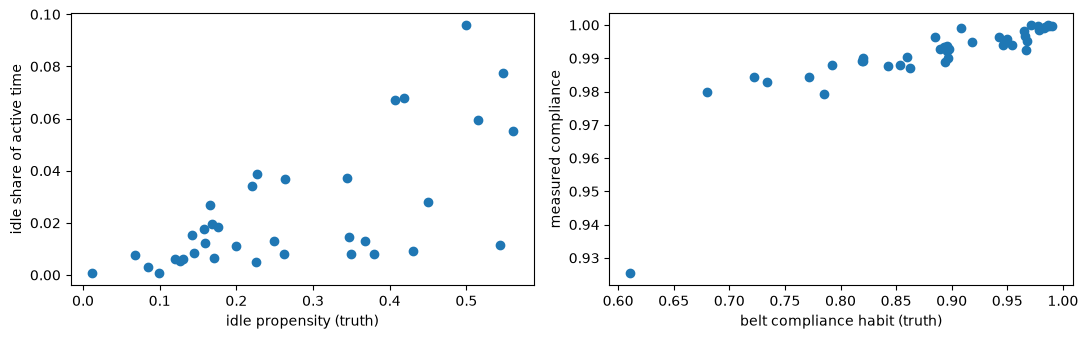

In [4]:
traits = read("truth_operator_traits").set_index("operator_id")
be, sc = read("behavior_events"), read("seatbelt_compliance")
idle = be[be.kind.isin(["idle", "high_rpm_idle"])]
idle_s = (idle.end_ts - idle.start_ts).dt.total_seconds().groupby(idle.operator_id).sum()
active_s = sc.groupby("operator_id")["active_s"].sum()
comp = 1 - sc.groupby("operator_id")["unbelted_active_s"].sum() / active_s
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].scatter(traits["idle_propensity"], (idle_s / active_s).reindex(traits.index)); ax[0].set_xlabel("idle propensity (truth)"); ax[0].set_ylabel("idle share of active time")
ax[1].scatter(traits["belt_compliance_p"], comp.reindex(traits.index)); ax[1].set_xlabel("belt compliance habit (truth)"); ax[1].set_ylabel("measured compliance")
plt.tight_layout()

## 4. Maintenance sensors drift with component wear; injected fault modes are visible (§7.5)

outcome,active,failed,fixed_before_failure
mode,,,
alternator_failure,2,6,3
cell_imbalance,0,1,1
filter_plugging,2,5,10
pump_wear,1,6,2
radiator_clogging,3,12,13
slow_tyre_leak,1,12,12
water_in_fuel,0,24,0


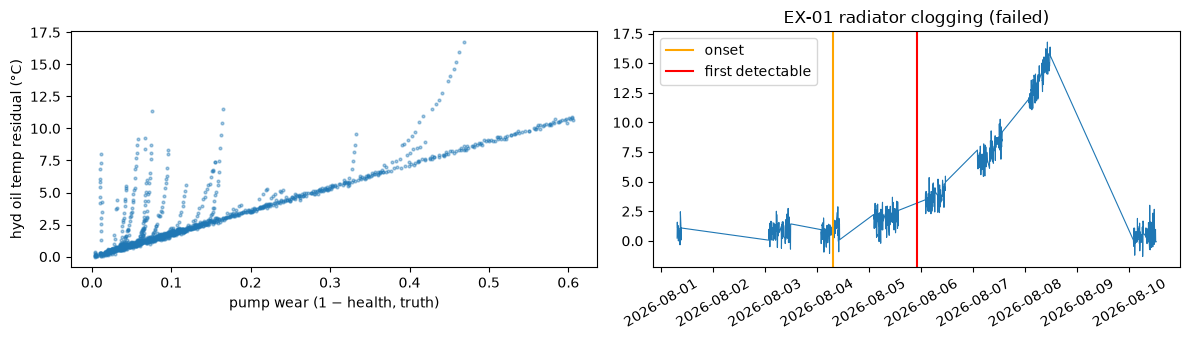

In [5]:
s, h = read("sensor_1min"), read("truth_component_health")
s["date"] = s["ts"].dt.tz_convert("Asia/Kolkata").dt.date
hyd = s[s.sensor_id == "hydraulic.oil_temp"].groupby(["machine_id", "date"])["resid"].mean().reset_index()
hyd = hyd.merge(h[h.component == "hydraulic_pump"], on=["machine_id", "date"])
fm = read("truth_fault_modes")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].scatter(1 - hyd["health"], hyd["resid"], s=4, alpha=0.4); ax[0].set_xlabel("pump wear (1 − health, truth)"); ax[0].set_ylabel("hyd oil temp residual (°C)")
ex = fm[fm["mode"] == "radiator_clogging"].head(1)
if len(ex):
    r = ex.iloc[0]
    cool = s[(s.machine_id == r.machine_id) & (s.sensor_id == "engine.coolant_temp")].set_index("ts")["resid"]
    win = cool[r.onset - pd.Timedelta(days=3): (r.resolved_at if pd.notna(r.resolved_at) else r.failure_time) + pd.Timedelta(days=1)]
    ax[1].plot(win.index, win.values, lw=0.8); ax[1].axvline(r.onset, color="orange", label="onset")
    if pd.notna(r.first_detectable): ax[1].axvline(r.first_detectable, color="red", label="first detectable")
    ax[1].tick_params(axis="x", labelrotation=30); ax[1].set_title(f"{r.machine_id} radiator clogging ({r.outcome})"); ax[1].legend()
plt.tight_layout()
fm.groupby(["mode", "outcome"]).size().unstack(fill_value=0)

## 5. Weather forecasts get less accurate with lead time (§7.3 Forecasts)

<Axes: title={'center': 'temp forecast MAE by lead time (h)'}, xlabel='lead_h'>

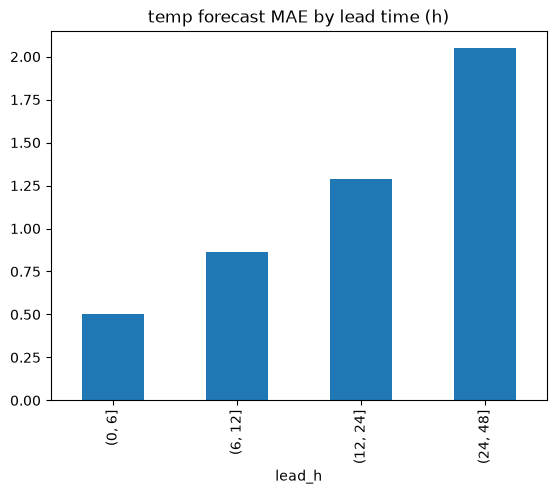

In [6]:
wf = read("weather_forecast"); truth = read("truth_weather_hourly")
tt = wf[wf["var"] == "temp_c"].merge(truth[["ts", "site_id", "temp_c"]], left_on=["valid_at", "site_id"], right_on=["ts", "site_id"])
tt["lead_h"] = (tt.valid_at - tt.issued_at).dt.total_seconds() / 3600
tt["abs_err"] = (tt.value - tt.temp_c).abs()
tt.groupby(pd.cut(tt.lead_h, [0, 6, 12, 24, 48]), observed=True)["abs_err"].mean().plot(kind="bar", title="temp forecast MAE by lead time (h)")